# 14 · From Photon Source to Quantum Gate (Perceval)

**Question:** how well does a photonic CNOT gate work with photons from real sources, and how much does a heralded gate lose against a post-selected one?
**Tool:** [Perceval](https://perceval.quandela.net) 1.3.1, a simulator of linear-optical circuits fed by imperfect photon sources. Its source model follows Pont et al., *Phys. Rev. X* 12, 031033 (2022): indistinguishability $M$, multi-photon component $g^{(2)}$, transmittance $T$ and brightness $b$.

A new simulator is only useful once it is trusted. The notebook first makes Perceval reproduce results derived by hand in earlier notebooks, then checks every new number against **our own independent code**: a permanent-based multiphoton simulation that takes nothing from Perceval except each gate's 6 × 6 unitary.

```
building blocks ─▶ imperfect sources (HOM) ─▶ three real sources ─▶ CNOT gates ─▶ rates, detectors ─▶ what limits each gate
```

**Sources:** ideal photons; the silicon pair source of Paesani et al. (notebook 10); the microring of Kues et al. 2017 (notebook 13). Assumed values are labelled where they enter.

In [1]:
import numpy as np
import perceval as pcvl

results = []   # every theory-vs-simulation check is recorded here

def check(label, sim, theory, tol=1e-3):
    """Compare a simulated number with its analytic value and record the result."""
    sim, theory = float(np.real(sim)), float(np.real(theory))
    ok = bool(np.isclose(sim, theory, atol=tol))
    results.append(ok)
    print(f"{'PASS' if ok else 'FAIL'}  {label}: simulation = {sim:.4f}, theory = {theory:.4f}")

In [2]:
from itertools import product
from math import factorial, comb
import matplotlib.pyplot as plt
print("Perceval", pcvl.__version__)

# Perceval drops every input state whose probability is below precision x (the largest one). The
# default, 1e-6, cuts real multi-photon events once vacuum dominates at low transmittance, so every
# run here uses 1e-12; what that still leaves out is a few 1e-9, hence the 1e-8 tolerance against
# our own code (section 4 reruns the hardest case at 1e-14 to show nothing hides in it).
PRECISION = 1e-12
TOL = 1e-8

_SIGNS = {}
def perm(A):
    """Glynn formula: perm(A) = 2^(1-n) sum_d (prod d) prod_j (sum_i d_i a_ij), d_0 = +1."""
    n = A.shape[0]
    if n == 0:
        return 1.0
    if n not in _SIGNS:
        _SIGNS[n] = np.array([(1,) + s for s in product((1, -1), repeat=n - 1)], dtype=float)
    d = _SIGNS[n]
    return np.sum(np.prod(d, axis=1) * np.prod(d @ A, axis=1)) / 2 ** (n - 1)

def fock_prob(U, n_in, n_out):
    """P(n_in -> n_out) for identical photons: |perm(U[out, in])|^2 / (prod n_in! prod n_out!)."""
    cols = [j for j, n in enumerate(n_in) for _ in range(n)]
    rows = [i for i, n in enumerate(n_out) for _ in range(n)]
    norm = np.prod([factorial(k) for k in list(n_in) + list(n_out)])
    return abs(perm(U[np.ix_(rows, cols)])) ** 2 / norm

def p2_from_g2(g2, b=1.0):
    """Two-photon probability: g2 = 2 p2 / (p1 + 2 p2)^2 with p1 + p2 = b, solved for p2."""
    return 0.0 if g2 == 0 else ((1 - g2 * b) - np.sqrt(1 - 2 * g2 * b)) / g2

Perceval 1.3.1


## 1. Perceval's building blocks reproduce earlier results

**Plain words:** Perceval describes a chip the way notebook 07 did: every component is a unitary matrix, and the probability of an output pattern is the squared permanent of a sub-matrix. Before it is trusted with noisy sources it has to give the textbook answers: the HOM dip (notebook 06), the Mach–Zehnder fringe and the three-mode tritter (notebook 07).

Conventions: `pcvl.BS()` is $\frac{1}{\sqrt2}\begin{pmatrix}1 & i\\ i & 1\end{pmatrix}$, `pcvl.BS.H()` is the Hadamard form of notebook 03, and components added later multiply from the left.

**Gap:** agreement on ideal photons shows that the API and its conventions are used correctly. It says nothing yet about the noise model, which section 2 tests.

**One sentence:** Perceval is a permanent calculator with a photon-source model attached.

In [3]:
BS = np.array([[1, 1j], [1j, 1]]) / np.sqrt(2)
check("BS() vs analytic matrix (max |diff|)", np.max(np.abs(np.array(pcvl.BS().compute_unitary()) - BS)), 0, tol=1e-12)
check("BS.H() vs Hadamard matrix (max |diff|)",
      np.max(np.abs(np.array(pcvl.BS.H().compute_unitary()) - np.array([[1, 1], [1, -1]]) / np.sqrt(2))), 0, tol=1e-12)

def ideal_probs(circuit, inp):
    be = pcvl.SLOSBackend()
    be.set_circuit(circuit)
    be.set_input_state(pcvl.BasicState(inp))
    return be.prob_distribution()

d = ideal_probs(pcvl.Circuit(2) // pcvl.BS(), [1, 1])
check("HOM dip: P(1,1)", d[pcvl.BasicState([1, 1])], 0.0, tol=1e-12)
check("HOM dip: P(2,0)", d[pcvl.BasicState([2, 0])], 0.5, tol=1e-12)

def mzi(phi):
    return pcvl.Circuit(2) // pcvl.BS() // (0, pcvl.PS(phi)) // pcvl.BS()

for phi in [0, np.pi / 3, np.pi / 2, np.pi]:
    U = np.array(mzi(phi).compute_unitary())
    pc = ideal_probs(mzi(phi), [1, 1])[pcvl.BasicState([1, 1])]
    check(f"MZI phi = {phi:.3f}: Perceval P(1,1) vs own permanent", pc, fock_prob(U, (1, 1), (1, 1)), tol=1e-12)
    check(f"MZI phi = {phi:.3f}: own permanent vs cos^2(phi)", fock_prob(U, (1, 1), (1, 1)), np.cos(phi) ** 2, tol=1e-12)

w = np.exp(2j * np.pi / 3)                                    # three-mode Fourier tritter
F3 = np.array([[w ** (j * k) for k in range(3)] for j in range(3)]) / np.sqrt(3)
d3 = ideal_probs(pcvl.Unitary(pcvl.Matrix(F3)), [1, 1, 0])
check("tritter |1,1,0>: P(2,0,0) vs 2|F00 F01|^2 = 2/9", d3[pcvl.BasicState([2, 0, 0])], 2 / 9, tol=1e-12)
check("tritter |1,1,0>: P(1,1,0) vs |1 + w|^2/9 = 1/9", d3[pcvl.BasicState([1, 1, 0])], 1 / 9, tol=1e-12)

PASS  BS() vs analytic matrix (max |diff|): simulation = 0.0000, theory = 0.0000
PASS  BS.H() vs Hadamard matrix (max |diff|): simulation = 0.0000, theory = 0.0000
PASS  HOM dip: P(1,1): simulation = 0.0000, theory = 0.0000
PASS  HOM dip: P(2,0): simulation = 0.5000, theory = 0.5000
PASS  MZI phi = 0.000: Perceval P(1,1) vs own permanent: simulation = 1.0000, theory = 1.0000
PASS  MZI phi = 0.000: own permanent vs cos^2(phi): simulation = 1.0000, theory = 1.0000
PASS  MZI phi = 1.047: Perceval P(1,1) vs own permanent: simulation = 0.2500, theory = 0.2500
PASS  MZI phi = 1.047: own permanent vs cos^2(phi): simulation = 0.2500, theory = 0.2500
PASS  MZI phi = 1.571: Perceval P(1,1) vs own permanent: simulation = 0.0000, theory = 0.0000
PASS  MZI phi = 1.571: own permanent vs cos^2(phi): simulation = 0.0000, theory = 0.0000
PASS  MZI phi = 3.142: Perceval P(1,1) vs own permanent: simulation = 1.0000, theory = 1.0000
PASS  MZI phi = 3.142: own permanent vs cos^2(phi): simulation = 1.0000, 

Perceval agrees with the analytic matrices and with our own permanent to machine precision.

## 2. Imperfect sources: indistinguishability, multi-photon noise and loss

**Plain words:** a real source falls short in three ways. Its photons are not perfectly identical: each photon sits in a shared wavepacket with probability $\sqrt M$ and in a private one otherwise, so two photons overlap with probability $M$. It sometimes emits an extra photon, with probability $p_2$ set by $g^{(2)} = 2p_2/(1+p_2)^2$. And photons are lost (transmittance $T$). The extra photon can be **distinguishable** (a private wavepacket, Perceval's default) or **identical** to the signal photon. For a pair source the identical case is the right one: multi-pair emission puts the extra photon into the same mode.

HOM visibility: $V = 1 - C(M)/C(M{=}0)$ at the same $g^{(2)}$ and $T$, where $C$ is the probability that both outputs click. Expected:
- $V = M$ without noise, whatever the loss;
- $V \approx M - g^{(2)}$ with a distinguishable noise photon and $V \approx M - g^{(2)}/2$ with an identical one (no loss);
- with loss and an identical noise photon, to first order (**derived here**): $V \approx M - g^{(2)}(1 - T/2)$.

*Derivation of the loss rule.* With $M = 1$ the noisy input is $|2,1\rangle$ with weight $2p_2 \approx g^{(2)}$. It gives a coincidence when all three photons survive ($T^3 \cdot \tfrac14$) or when the lone photon is lost and the pair splits ($T^2(1-T)\cdot\tfrac12$); losing one photon of the pair leaves an ideal $|1,1\rangle$, which never coincides. Divided by the reference $T^2/2$, the penalty is $g^{(2)}(T/2 + 1 - T) = g^{(2)}(1 - T/2)$: $g^{(2)}/2$ without loss, $g^{(2)}$ under heavy loss.

Our own model below implements the same physics without any Perceval backend: wavepacket labels, loss photon by photon, and each wavepacket group sent through the beam splitter on its own.

**Gap:** the source model treats every imperfection as a mixture of perfectly overlapping and fully distinct wavepackets; partial overlaps and time-dependent noise are outside it. The rules of thumb are first order and are compared with the exact model.

**One sentence:** distinguishability lowers the visibility one for one; an identical noise photon costs half its $g^{(2)}$ without loss and almost all of it under heavy loss.

In [4]:
def noise(M, g2, T=1.0, identical_noise=True, b=1.0):
    return pcvl.NoiseModel(brightness=b, indistinguishability=M, g2=g2,
                           g2_distinguishable=not identical_noise, transmittance=T)

def hom_coincidence(nm):
    """Perceval: P(both outputs click) for |1,1> on BS(), threshold detectors, no photon filter."""
    p = pcvl.Processor("SLOS", pcvl.Circuit(2) // pcvl.BS(), noise=nm)
    p.with_input(pcvl.BasicState([1, 1]))
    p.min_detected_photons_filter(0)
    res = p.probs(precision=PRECISION)["results"]
    return sum(pr for s, pr in res.items() if s[0] >= 1 and s[1] >= 1)

def hom_V(M, g2, T=1.0, identical_noise=True):
    return 1 - hom_coincidence(noise(M, g2, T, identical_noise)) / hom_coincidence(noise(0.0, g2, T, identical_noise))

def own_coincidence(M, g2, T=1.0, identical_noise=True):
    """Own code: signal in the shared wavepacket 'c' with prob sqrt(M), else private; noise photon
    (prob p2) in 'c' if identical, else private. Each photon survives with prob T."""
    p2, sM = p2_from_g2(g2), np.sqrt(M)
    def outcomes(src):
        out = []
        for common, extra in product([True, False], [False, True]):
            pr = (sM if common else 1 - sM) * (p2 if extra else 1 - p2)
            if pr > 0:
                labels = ["c" if common else f"s{src}"]
                if extra:
                    labels.append("c" if identical_noise else f"n{src}")
                out.append((pr, labels))
        return out
    C = 0.0
    for (pa, la), (pb, lb) in product(outcomes(0), outcomes(1)):
        photons = [(0, l) for l in la] + [(1, l) for l in lb]
        for keep in product([True, False], repeat=len(photons)):         # loss, photon by photon
            pk = np.prod([T if k else 1 - T for k in keep])
            if pk == 0:
                continue
            kept = [ph for ph, k in zip(photons, keep) if k]
            dist = {(0, 0): 1.0}
            for lab in {l for _, l in kept}:                                # each wavepacket on its own
                n_in = (sum(1 for m, l in kept if l == lab and m == 0), sum(1 for m, l in kept if l == lab and m == 1))
                n = sum(n_in)
                new = {}
                for (a, c), q in dist.items():
                    for k in range(n + 1):
                        new[(a + k, c + n - k)] = new.get((a + k, c + n - k), 0.0) + q * fock_prob(BS, n_in, (k, n - k))
                dist = new
            C += pa * pb * pk * sum(q for (a, c), q in dist.items() if a >= 1 and c >= 1)
    return C

def own_V(M, g2, T=1.0, identical_noise=True):
    return 1 - own_coincidence(M, g2, T, identical_noise) / own_coincidence(0.0, g2, T, identical_noise)

def V_closed_form(g2, identical_noise):
    """M = 1, T = 1, cases counted by hand (one source with a noise photon: weight 2 p1 p2; both: p2^2)."""
    p2 = p2_from_g2(g2)
    p1 = 1 - p2
    if identical_noise:
        Cs, Cd = 0.5 * p1 * p2 + 0.25 * p2 ** 2, p1 ** 2 / 2 + 1.5 * p1 * p2 + 0.75 * p2 ** 2
    else:
        Cs, Cd = p1 * p2 + 0.75 * p2 ** 2, p1 ** 2 / 2 + 1.5 * p1 * p2 + 0.875 * p2 ** 2
    return 1 - Cs / Cd

for M in [1.0, 0.9, 0.5]:
    check(f"V(M = {M}, g2 = 0) vs M", hom_V(M, 0.0), M, tol=TOL)

print(f"{'g2':>5} | {'V dist.':>8} {'M - g2':>7} | {'V ident.':>8} {'M - g2/2':>8} | penalty ratio ident./dist.")
for g2 in [0.02, 0.05, 0.1]:
    Vd, Vi = hom_V(1.0, g2, identical_noise=False), hom_V(1.0, g2)
    check(f"g2 = {g2}, distinguishable noise: Perceval - own model", Vd - own_V(1.0, g2, identical_noise=False), 0, tol=TOL)
    check(f"g2 = {g2}, distinguishable noise: Perceval - closed form", Vd - V_closed_form(g2, False), 0, tol=TOL)
    check(f"g2 = {g2}, identical noise: Perceval - own model", Vi - own_V(1.0, g2), 0, tol=TOL)
    check(f"g2 = {g2}, identical noise: Perceval - closed form", Vi - V_closed_form(g2, True), 0, tol=TOL)
    print(f"{g2:5.2f} | {Vd:8.4f} {1 - g2:7.3f} | {Vi:8.4f} {1 - g2 / 2:8.3f} | {(1 - Vi) / (1 - Vd):.3f}")

PASS  V(M = 1.0, g2 = 0) vs M: simulation = 1.0000, theory = 1.0000
PASS  V(M = 0.9, g2 = 0) vs M: simulation = 0.9000, theory = 0.9000
PASS  V(M = 0.5, g2 = 0) vs M: simulation = 0.5000, theory = 0.5000
   g2 |  V dist.  M - g2 | V ident. M - g2/2 | penalty ratio ident./dist.
PASS  g2 = 0.02, distinguishable noise: Perceval - own model: simulation = 0.0000, theory = 0.0000
PASS  g2 = 0.02, distinguishable noise: Perceval - closed form: simulation = 0.0000, theory = 0.0000
PASS  g2 = 0.02, identical noise: Perceval - own model: simulation = 0.0000, theory = 0.0000
PASS  g2 = 0.02, identical noise: Perceval - closed form: simulation = 0.0000, theory = 0.0000
 0.02 |   0.9798   0.980 |   0.9899    0.990 | 0.499
PASS  g2 = 0.05, distinguishable noise: Perceval - own model: simulation = -0.0000, theory = 0.0000
PASS  g2 = 0.05, distinguishable noise: Perceval - closed form: simulation = 0.0000, theory = 0.0000
PASS  g2 = 0.05, identical noise: Perceval - own model: simulation = 0.0000, the

Both rules of thumb hold to within 0.005 for $g^{(2)} \le 0.1$, and the identical noise photon costs almost exactly half as much visibility as a distinguishable one. Now the loss rule, with the measured $g^{(2)} = 0.053$ of the Paesani source:

In [5]:
G2P = 0.053
print(f"{'T':>6} | {'penalty 1 - V':>13} {'g2(1 - T/2)':>11} {'g2/2':>6}")
penalty = {}
for T in [1.0, 0.5, 0.126]:
    V = hom_V(1.0, G2P, T)
    check(f"T = {T}: Perceval - own lossy model", V - own_V(1.0, G2P, T), 0, tol=TOL)
    check(f"T = {T}: V(g2 = 0) = M (loss alone leaves V unchanged)", hom_V(0.9, 0.0, T), 0.9, tol=TOL)
    check(f"T = {T}: penalty vs first-order rule g2(1 - T/2)", 1 - V, G2P * (1 - T / 2), tol=0.003)
    penalty[T] = 1 - V
    print(f"{T:6.3f} | {1 - V:13.4f} {G2P * (1 - T / 2):11.4f} {G2P / 2:6.4f}")

# notebook 10 (QuTiP, multimode pair statistics with a click herald) printed a multi-photon
# visibility of 0.953 at the measured heralding efficiency 0.126: an independent model of the same source
check("penalty at T = 0.126 vs notebook 10 (1 - 0.953)", penalty[0.126], 1 - 0.953, tol=0.002)

     T | penalty 1 - V g2(1 - T/2)   g2/2
PASS  T = 1.0: Perceval - own lossy model: simulation = 0.0000, theory = 0.0000
PASS  T = 1.0: V(g2 = 0) = M (loss alone leaves V unchanged): simulation = 0.9000, theory = 0.9000
PASS  T = 1.0: penalty vs first-order rule g2(1 - T/2): simulation = 0.0269, theory = 0.0265
 1.000 |        0.0269      0.0265 0.0265
PASS  T = 0.5: Perceval - own lossy model: simulation = 0.0000, theory = 0.0000
PASS  T = 0.5: V(g2 = 0) = M (loss alone leaves V unchanged): simulation = 0.9000, theory = 0.9000
PASS  T = 0.5: penalty vs first-order rule g2(1 - T/2): simulation = 0.0390, theory = 0.0398
 0.500 |        0.0390      0.0398 0.0265
PASS  T = 0.126: Perceval - own lossy model: simulation = 0.0000, theory = 0.0000
PASS  T = 0.126: V(g2 = 0) = M (loss alone leaves V unchanged): simulation = 0.9000, theory = 0.9000
PASS  T = 0.126: penalty vs first-order rule g2(1 - T/2): simulation = 0.0476, theory = 0.0497
 0.126 |        0.0476      0.0497 0.0265
PASS  pena

Under the source's heavy loss ($T = 0.126$) the multi-photon penalty almost doubles, from 0.027 to 0.048, because a lost photon lets the remaining pair split and fake a coincidence. The first-order rule follows this within 0.003, and the completely different QuTiP model of notebook 10 gives the same penalty.

## 3. Three source sets

| Set | $M$ | $g^{(2)}$ | $T$ | Origin |
|---|---|---|---|---|
| S_ideal | 1 | 0 | 1 | perfect photons |
| S_paesani | 0.99 | 0.053 | 0.126 | Paesani et al., *Nat. Commun.* 11, 2505 (2020): JSI purity 0.9904, heralded $g^{(2)}$, heralding efficiency, all measured (notebook 10) |
| S_ring | 0.92 | 0.02 | 0.954 | $M$: Kues et al. 2017, Fig. 2b inset, $g^{(2)}$ = 1.92 per resonance → purity 1/1.086 (**assumed** $M$ = purity); $g^{(2)}$: design D5 of the light-source project (**assumed**); $T$: escape efficiency of notebook 13 (**assumed**: no further loss) |

All three use an identical noise photon. **Assumed** brightness 1 (every source delivers a photon every pulse) until section 5.

**Gap:** S_ring combines a measured purity, a designed $g^{(2)}$ and an on-chip-only efficiency, so it is the best case for that chip rather than a measured source.

**One sentence:** one perfect source, one measured source and one designed best case.

In [6]:
SOURCES = {"S_ideal": (1.0, 0.0, 1.0), "S_paesani": (0.99, 0.053, 0.126), "S_ring": (0.92, 0.02, 0.954)}
print(f"{'set':>10} | {'V':>7} {'M - g2/2':>8} {'M - g2(1 - T/2)':>15}")
for name, (M, g2, T) in SOURCES.items():
    V = hom_V(M, g2, T)
    check(f"{name}: HOM visibility, Perceval - own model", V - own_V(M, g2, T), 0, tol=TOL)
    print(f"{name:>10} | {V:7.4f} {M - g2 / 2:8.4f} {M - g2 * (1 - T / 2):15.4f}")

       set |       V M - g2/2 M - g2(1 - T/2)
PASS  S_ideal: HOM visibility, Perceval - own model: simulation = 0.0000, theory = 0.0000
   S_ideal |  1.0000   1.0000          1.0000
PASS  S_paesani: HOM visibility, Perceval - own model: simulation = 0.0000, theory = 0.0000
 S_paesani |  0.9431   0.9635          0.9403
PASS  S_ring: HOM visibility, Perceval - own model: simulation = 0.0000, theory = 0.0000
    S_ring |  0.9108   0.9100          0.9095


S_paesani reaches $V = 0.943$, in line with the measured two-source visibility 0.96 ± 0.02. Its loss makes the lossless rule $M - g^{(2)}/2$ 0.020 too optimistic, while the loss rule is within 0.003. S_ring is limited by its purity ($V = 0.911$), not by noise or loss.

## 4. Post-selected vs heralded CNOT

Dual-rail qubits: qubit 0 = modes 0, 1; qubit 1 = modes 2, 3; |0⟩ = photon in the first mode of the pair. Both gates come from Perceval's catalogue:
- **post-selected** (`postprocessed cnot`): Ralph et al., *Phys. Rev. A* 65, 062324 (2002) and Hofmann & Takeuchi, *Phys. Rev. A* 66, 024308 (2002). Beam splitters of reflectivity 1/3 and two empty ancilla modes; a run counts only if each qubit ends with exactly one photon. Success 1/9.
- **heralded** (`heralded cnot`): Knill, *Phys. Rev. A* 66, 052306 (2002). Two extra photons; success is announced by exactly one photon in each of two herald modes, without touching the qubits. Success 2/27.

**Plain words:** both gates make photons interfere on beam splitters and keep only the runs in which the interference did the right thing. The post-selected gate finds out by looking at its output, which destroys it; the heralded gate finds out from two extra photons and leaves its output usable. That announcement costs two more photons, and every lost photon can fake it.

**Truth-table fidelity** = average over the four inputs of P(correct output | gate event):
- **main figure, F:** the gate event is what the gate itself reports, the heralds for the heralded gate (it is used without looking at its output) and the post-selection for the post-selected gate;
- **secondary, F_ps (post-selected):** the heralded gate's fidelity when additionally post-selected on one photon per qubit (a two-qubit coincidence). For the post-selected gate F_ps = F.

**Closed form (derived here)**, post-selected gate, no noise or loss. With control 0 the two photons never meet: F = 1. With control 1 they meet at a 1/3 beam splitter; from the gate matrix (entries ±1/√3) the correct output has probability 1/9 for identical and for distinguishable photons, the wrong one 0 for identical photons (two paths cancel) and 2/9 for distinguishable ones. Identical with probability $M$:

$$F(\text{control} = 1) = \frac{1}{1 + 2(1-M)},\qquad F = 1 - \frac{1-M}{3-2M}$$

**Gap:** a truth table is measured in the computational basis only. A gate that flips the right bits but scrambles phases would still score 1; the process fidelity needs superposition inputs as well. Detectors resolve photon number unless stated (section 5 tests click detectors).

**One sentence:** the heralded gate pays for its announcement with two extra photons, and every lost photon turns into a false announcement.

In [7]:
GATES = {"post-selected": {"catalog": "postprocessed cnot", "n": 2, "S_ideal": 1 / 9},
         "heralded": {"catalog": "heralded cnot", "n": 4, "S_ideal": 2 / 27}}
LOGICAL = ((1, 0, 1, 0), (1, 0, 0, 1), (0, 1, 1, 0), (0, 1, 0, 1))      # |00>, |01>, |10>, |11>
CNOT = {0: 0, 1: 1, 2: 3, 3: 2}                                          # target flips if control = 1
EXP = {g: pcvl.catalog[d["catalog"]].build_experiment() for g, d in GATES.items()}
UNITARY = {g: np.array(e.unitary_circuit().compute_unitary()) for g, e in EXP.items()}
HERALDS = {g: dict(e.heralds) for g, e in EXP.items()}                   # output mode -> required photons
assert HERALDS == {"post-selected": {4: 0, 5: 0}, "heralded": {4: 1, 5: 1}}
assert {g: dict(e.in_heralds) for g, e in EXP.items()} == HERALDS        # photons injected in modes 4, 5

# the same post-selected gate with threshold (click) detectors on all six modes, used in section 5
EXP_TH = pcvl.catalog["postprocessed cnot"].build_experiment()
for m in range(6):
    EXP_TH.add(m, pcvl.Detector.threshold())
assert EXP_TH.detection_type == pcvl.DetectionType.Threshold

def is_logical(s):
    return s[0] + s[1] == 1 and s[2] + s[3] == 1

def summarize(per_input):
    """per_input: P(event), P(event and one photon per qubit), joint probabilities of the 4 logical outputs."""
    return {"F": np.mean([d["row"][CNOT[i]] / d["P_event"] for i, d in enumerate(per_input)]),
            "F_ps": np.mean([d["row"][CNOT[i]] / d["P_ps"] for i, d in enumerate(per_input)]),
            "S": np.mean([d["P_event"] for d in per_input]),
            "S_ps": np.mean([d["P_ps"] for d in per_input]),
            "table": np.array([[x / d["P_ps"] for x in d["row"]] for d in per_input])}

def run_perceval(gate, M, g2, T, precision=PRECISION, threshold=False, b=1.0):
    per_input = []
    for inp in LOGICAL:
        p = pcvl.Processor("SLOS", EXP_TH if threshold else EXP[gate], noise=noise(M, g2, T, b=b))
        p.with_input(pcvl.BasicState(list(inp)))
        p.min_detected_photons_filter(0)                    # condition on the gate event only
        r = p.probs(precision=precision)
        res, perf = r["results"], r["global_perf"]          # res is normalised to the event, perf = P(event)
        per_input.append({"P_event": perf, "row": [perf * res.get(pcvl.BasicState(list(o)), 0.0) for o in LOGICAL],
                          "P_ps": perf * sum(pr for s, pr in res.items() if is_logical(s))})
    return summarize(per_input)

In [8]:
_GROUP = {}
def group_distribution(gate, n_in):
    """Output distribution of identical photons with input occupation n_in through the gate unitary."""
    if (gate, n_in) not in _GROUP:
        U, dist = UNITARY[gate], {}
        n = sum(n_in)
        def patterns(k, m):
            if m == 1:
                yield (k,)
                return
            for j in range(k, -1, -1):
                for rest in patterns(k - j, m - 1):
                    yield (j,) + rest
        for out in patterns(n, len(n_in)):
            pr = fock_prob(U, n_in, out)
            if pr > 1e-18:
                dist[out] = pr
        _GROUP[(gate, n_in)] = dist
    return _GROUP[(gate, n_in)]

def convolve(d1, d2):
    out = {}
    for a, pa in d1.items():
        for c, pc in d2.items():
            k = tuple(x + y for x, y in zip(a, c))
            out[k] = out.get(k, 0.0) + pa * pc
    return out

def run_own(gate, M, g2, T, threshold=False, b=1.0):
    """Own multiphoton model: one source per injected photon (data and herald photons alike).
    A source is empty with prob 1 - b, emits one photon with p1 = b - p2, two with p2. The signal
    photon is in the shared wavepacket with prob sqrt(M), else private; the noise photon is shared.
    Private photons interfere with nobody, so their distributions are convolved. Uniform loss
    commutes with a lossless circuit and is applied as binomial loss on every output mode."""
    p2, sM, m = p2_from_g2(g2, b), np.sqrt(M), 6
    per_input = []
    for inp in LOGICAL:
        occ = list(inp) + [HERALDS[gate][4], HERALDS[gate][5]]
        modes = [j for j, n in enumerate(occ) for _ in range(n)]
        choices = []                                        # (prob, shared photons, private photon?)
        for _ in modes:
            c = [(1 - b, 0, False)] if b < 1 else []
            for common, extra in product((True, False), (False, True)):
                pr = (sM if common else 1 - sM) * (p2 if extra else b - p2)
                if pr > 0:
                    c.append((pr, int(common) + int(extra), not common))
            choices.append(c)
        total = {}
        for combo in product(*choices):
            wgt, shared, dist = np.prod([c[0] for c in combo]), [0] * m, None
            for j, (_, nc, private) in zip(modes, combo):
                shared[j] += nc
                if private:
                    single = tuple(1 if k == j else 0 for k in range(m))
                    dist = group_distribution(gate, single) if dist is None else convolve(dist, group_distribution(gate, single))
            cd = group_distribution(gate, tuple(shared))
            dist = cd if dist is None else convolve(dist, cd)
            for s, pr in dist.items():
                total[s] = total.get(s, 0.0) + wgt * pr
        if T < 1:                                           # loss
            lossy = {}
            for s, pr in total.items():
                for kept in product(*[range(n + 1) for n in s]):
                    w_ = np.prod([comb(n, k) * T ** k * (1 - T) ** (n - k) for n, k in zip(s, kept)])
                    lossy[kept] = lossy.get(kept, 0.0) + pr * w_
            total = lossy
        if threshold:                                       # click detectors: n -> min(n, 1)
            clicks = {}
            for s, pr in total.items():
                k = tuple(min(n, 1) for n in s)
                clicks[k] = clicks.get(k, 0.0) + pr
            total = clicks
        P_event = P_ps = 0.0
        row = [0.0] * 4
        for s, pr in total.items():
            if s[4] != HERALDS[gate][4] or s[5] != HERALDS[gate][5]:
                continue
            if gate == "post-selected" and not is_logical(s[:4]):
                continue
            P_event += pr
            if is_logical(s[:4]):
                P_ps += pr
                row[LOGICAL.index(tuple(s[:4]))] += pr
        per_input.append({"P_event": P_event, "P_ps": P_ps, "row": row})
    return summarize(per_input)

def compare(label, a, o, tol=TOL):
    """Perceval result a vs own model o; returns the largest fidelity or table deviation."""
    check(f"{label}: F, Perceval - own", a["F"] - o["F"], 0, tol=tol)
    check(f"{label}: F_ps, Perceval - own", a["F_ps"] - o["F_ps"], 0, tol=tol)
    check(f"{label}: success, Perceval/own - 1", a["S"] / o["S"] - 1, 0, tol=TOL)
    check(f"{label}: truth table, max |diff|", np.max(np.abs(a["table"] - o["table"])), 0, tol=tol)
    return max(abs(a["F"] - o["F"]), abs(a["F_ps"] - o["F_ps"]), np.max(np.abs(a["table"] - o["table"])))

**Ideal photons and loss alone.** With perfect photons both gates must reach their textbook success probability with a perfect truth table. Loss alone ($M = 1$, $g^{(2)} = 0$) must leave the post-selected fidelity at 1 and lower only the rate, by $T^n$ for $n$ photons. The same holds for the heralded gate's F_ps, but not for its main figure F: a herald does not notice that a data photon is missing.

In [9]:
for g, d in GATES.items():
    r = run_perceval(g, 1.0, 0.0, 1.0)
    check(f"{g}, ideal: success vs {'1/9' if d['n'] == 2 else '2/27'}", r["S"], d["S_ideal"], tol=1e-12)
    check(f"{g}, ideal: F vs 1", r["F"], 1.0, tol=TOL)
    check(f"{g}, ideal: truth table vs CNOT (max |diff|)",
          np.max(np.abs(r["table"] - np.eye(4)[[CNOT[i] for i in range(4)]])), 0, tol=TOL)

for T in [0.954, 0.5, 0.126]:
    ps, he = run_perceval("post-selected", 1.0, 0.0, T), run_perceval("heralded", 1.0, 0.0, T)
    check(f"loss T = {T}: post-selected F stays 1", ps["F"], 1.0, tol=TOL)
    check(f"loss T = {T}: post-selected success = T^2/9 (ratio)", ps["S"] / (T ** 2 / 9), 1.0, tol=TOL)
    check(f"loss T = {T}: heralded F_ps stays 1", he["F_ps"], 1.0, tol=TOL)
    check(f"loss T = {T}: heralded F_ps success = 2 T^4/27 (ratio)", he["S_ps"] / (2 * T ** 4 / 27), 1.0, tol=TOL)
    compare(f"heralded, loss T = {T}", he, run_own("heralded", 1.0, 0.0, T))
    print(f"      heralded main figure F = {he['F']:.4f} at T = {T}")

PASS  post-selected, ideal: success vs 1/9: simulation = 0.1111, theory = 0.1111
PASS  post-selected, ideal: F vs 1: simulation = 1.0000, theory = 1.0000
PASS  post-selected, ideal: truth table vs CNOT (max |diff|): simulation = 0.0000, theory = 0.0000


PASS  heralded, ideal: success vs 2/27: simulation = 0.0741, theory = 0.0741


PASS  heralded, ideal: F vs 1: simulation = 1.0000, theory = 1.0000
PASS  heralded, ideal: truth table vs CNOT (max |diff|): simulation = 0.0000, theory = 0.0000
PASS  loss T = 0.954: post-selected F stays 1: simulation = 1.0000, theory = 1.0000
PASS  loss T = 0.954: post-selected success = T^2/9 (ratio): simulation = 1.0000, theory = 1.0000
PASS  loss T = 0.954: heralded F_ps stays 1: simulation = 1.0000, theory = 1.0000
PASS  loss T = 0.954: heralded F_ps success = 2 T^4/27 (ratio): simulation = 1.0000, theory = 1.0000
PASS  heralded, loss T = 0.954: F, Perceval - own: simulation = 0.0000, theory = 0.0000
PASS  heralded, loss T = 0.954: F_ps, Perceval - own: simulation = 0.0000, theory = 0.0000
PASS  heralded, loss T = 0.954: success, Perceval/own - 1: simulation = 0.0000, theory = 0.0000
PASS  heralded, loss T = 0.954: truth table, max |diff|: simulation = 0.0000, theory = 0.0000
      heralded main figure F = 0.8307 at T = 0.954
PASS  loss T = 0.5: post-selected F stays 1: simulat

At $T = 0.126$ the heralded gate's main fidelity is 0.005: almost every herald comes from a run that lost a data photon. Now the three source sets:

In [10]:
sets = {}
LABELS = ("00", "01", "10", "11")
for name, (M, g2, T) in SOURCES.items():
    for g in GATES:
        r = run_perceval(g, M, g2, T)
        compare(f"{name} / {g}", r, run_own(g, M, g2, T))
        sets[(name, g)] = r
print(f"\n{'source / gate':>26} | {'F':>6} {'F_ps':>6} | {'success':>9}")
for (name, g), r in sets.items():
    fps = f"{r['F_ps']:6.3f}" if g == "heralded" else f"{'= F':>6}"
    print(f"{name + ' / ' + g:>26} | {r['F']:6.3f} {fps} | {r['S']:9.3e}")
for g in GATES:
    print(f"\ntruth table, S_ring / {g} (rows: input, columns: output, given one photon per qubit)")
    print("        " + "  ".join(f"{l:>6}" for l in LABELS))
    for i, row in enumerate(sets[("S_ring", g)]["table"]):
        print(f"    {LABELS[i]}  " + "  ".join(f"{x:6.4f}" for x in row))

PASS  S_ideal / post-selected: F, Perceval - own: simulation = 0.0000, theory = 0.0000


PASS  S_ideal / post-selected: F_ps, Perceval - own: simulation = 0.0000, theory = 0.0000
PASS  S_ideal / post-selected: success, Perceval/own - 1: simulation = 0.0000, theory = 0.0000
PASS  S_ideal / post-selected: truth table, max |diff|: simulation = 0.0000, theory = 0.0000
PASS  S_ideal / heralded: F, Perceval - own: simulation = 0.0000, theory = 0.0000
PASS  S_ideal / heralded: F_ps, Perceval - own: simulation = 0.0000, theory = 0.0000
PASS  S_ideal / heralded: success, Perceval/own - 1: simulation = 0.0000, theory = 0.0000
PASS  S_ideal / heralded: truth table, max |diff|: simulation = 0.0000, theory = 0.0000
PASS  S_paesani / post-selected: F, Perceval - own: simulation = 0.0000, theory = 0.0000
PASS  S_paesani / post-selected: F_ps, Perceval - own: simulation = 0.0000, theory = 0.0000
PASS  S_paesani / post-selected: success, Perceval/own - 1: simulation = 0.0000, theory = 0.0000
PASS  S_paesani / post-selected: truth table, max |diff|: simulation = 0.0000, theory = 0.0000


PASS  S_paesani / heralded: F, Perceval - own: simulation = -0.0000, theory = 0.0000
PASS  S_paesani / heralded: F_ps, Perceval - own: simulation = 0.0000, theory = 0.0000
PASS  S_paesani / heralded: success, Perceval/own - 1: simulation = -0.0000, theory = 0.0000
PASS  S_paesani / heralded: truth table, max |diff|: simulation = 0.0000, theory = 0.0000
PASS  S_ring / post-selected: F, Perceval - own: simulation = 0.0000, theory = 0.0000
PASS  S_ring / post-selected: F_ps, Perceval - own: simulation = 0.0000, theory = 0.0000
PASS  S_ring / post-selected: success, Perceval/own - 1: simulation = 0.0000, theory = 0.0000
PASS  S_ring / post-selected: truth table, max |diff|: simulation = 0.0000, theory = 0.0000


PASS  S_ring / heralded: F, Perceval - own: simulation = 0.0000, theory = 0.0000
PASS  S_ring / heralded: F_ps, Perceval - own: simulation = 0.0000, theory = 0.0000
PASS  S_ring / heralded: success, Perceval/own - 1: simulation = -0.0000, theory = 0.0000
PASS  S_ring / heralded: truth table, max |diff|: simulation = 0.0000, theory = 0.0000

             source / gate |      F   F_ps |   success
   S_ideal / post-selected |  1.000    = F | 1.111e-01
        S_ideal / heralded |  1.000  1.000 | 7.407e-02
 S_paesani / post-selected |  0.929    = F | 2.029e-03
      S_paesani / heralded |  0.005  0.942 | 5.301e-03
    S_ring / post-selected |  0.930    = F | 1.074e-01
         S_ring / heralded |  0.705  0.954 | 7.830e-02

truth table, S_ring / post-selected (rows: input, columns: output, given one photon per qubit)
            00      01      10      11
    00  0.9991  0.0000  0.0009  0.0000
    01  0.0000  0.9991  0.0000  0.0009
    10  0.0000  0.0000  0.1392  0.8608
    11  0.0000  0.00

The post-selected gate reaches F ≈ 0.93 with both real sources. For the heralded gate the main figure is 0.005 with S_paesani (loss) and 0.705 with S_ring; post-selected on one photon per qubit it would be 0.94–0.95. The post-selected gate errs only when the control is 1 (the target fails to flip), because only then do the photons meet; the heralded gate errs for both control values.

**Precision.** At 1e-12 Perceval leaves out input states below 1e-12 × the largest one, which shifts the heralded results by a few 1e-9. Rerunning every heralded case at 1e-14 must bring Perceval and our model together to better than 1e-10:

In [11]:
dev = []
for name, (M, g2, T) in SOURCES.items():
    dev.append(compare(f"{name} / heralded at 1e-14", run_perceval("heralded", M, g2, T, precision=1e-14),
                       run_own("heralded", M, g2, T), tol=1e-10))
print(f"largest |Perceval - own model| at precision 1e-14: {max(dev):.1e}")

PASS  S_ideal / heralded at 1e-14: F, Perceval - own: simulation = 0.0000, theory = 0.0000
PASS  S_ideal / heralded at 1e-14: F_ps, Perceval - own: simulation = 0.0000, theory = 0.0000
PASS  S_ideal / heralded at 1e-14: success, Perceval/own - 1: simulation = 0.0000, theory = 0.0000
PASS  S_ideal / heralded at 1e-14: truth table, max |diff|: simulation = 0.0000, theory = 0.0000


PASS  S_paesani / heralded at 1e-14: F, Perceval - own: simulation = 0.0000, theory = 0.0000
PASS  S_paesani / heralded at 1e-14: F_ps, Perceval - own: simulation = 0.0000, theory = 0.0000
PASS  S_paesani / heralded at 1e-14: success, Perceval/own - 1: simulation = -0.0000, theory = 0.0000
PASS  S_paesani / heralded at 1e-14: truth table, max |diff|: simulation = 0.0000, theory = 0.0000


PASS  S_ring / heralded at 1e-14: F, Perceval - own: simulation = 0.0000, theory = 0.0000
PASS  S_ring / heralded at 1e-14: F_ps, Perceval - own: simulation = 0.0000, theory = 0.0000
PASS  S_ring / heralded at 1e-14: success, Perceval/own - 1: simulation = -0.0000, theory = 0.0000
PASS  S_ring / heralded at 1e-14: truth table, max |diff|: simulation = 0.0000, theory = 0.0000
largest |Perceval - own model| at precision 1e-14: 1.8e-11


**Sweeps** at $T = 1$: fidelity against indistinguishability ($g^{(2)} = 0$) and against $g^{(2)}$ ($M = 1$), every point checked against our own model, and the post-selected M sweep against the closed form.

44 sweep points checked against the own model: all PASS
PASS  post-selected, M = 0.8: F vs 1 - (1-M)/(3-2M): simulation = 0.8571, theory = 0.8571
PASS  post-selected, M = 0.82: F vs 1 - (1-M)/(3-2M): simulation = 0.8676, theory = 0.8676
PASS  post-selected, M = 0.84: F vs 1 - (1-M)/(3-2M): simulation = 0.8788, theory = 0.8788
PASS  post-selected, M = 0.86: F vs 1 - (1-M)/(3-2M): simulation = 0.8906, theory = 0.8906
PASS  post-selected, M = 0.88: F vs 1 - (1-M)/(3-2M): simulation = 0.9032, theory = 0.9032
PASS  post-selected, M = 0.9: F vs 1 - (1-M)/(3-2M): simulation = 0.9167, theory = 0.9167
PASS  post-selected, M = 0.92: F vs 1 - (1-M)/(3-2M): simulation = 0.9310, theory = 0.9310
PASS  post-selected, M = 0.94: F vs 1 - (1-M)/(3-2M): simulation = 0.9464, theory = 0.9464
PASS  post-selected, M = 0.96: F vs 1 - (1-M)/(3-2M): simulation = 0.9630, theory = 0.9630
PASS  post-selected, M = 0.98: F vs 1 - (1-M)/(3-2M): simulation = 0.9808, theory = 0.9808
PASS  post-selected, M = 1.0: F vs 1

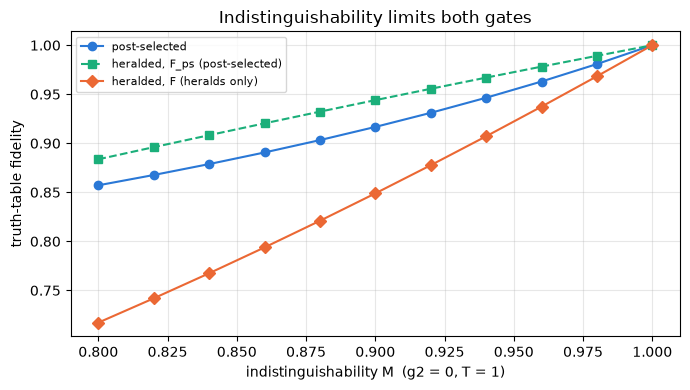

In [12]:
M_grid = np.round(np.linspace(0.80, 1.00, 11), 3)
g2_grid = np.round(np.linspace(0.0, 0.10, 11), 3)
sweep = {}
for g in GATES:
    for key, grid in (("M", M_grid), ("g2", g2_grid)):
        pts = []
        for x in grid:
            M, g2 = (x, 0.0) if key == "M" else (1.0, x)
            r, o = run_perceval(g, M, g2, 1.0), run_own(g, M, g2, 1.0)
            results.append(bool(abs(r["F"] - o["F"]) < TOL and abs(r["F_ps"] - o["F_ps"]) < TOL))
            pts.append(r)
        sweep[(g, key)] = pts
print(f"{2 * (len(M_grid) + len(g2_grid))} sweep points checked against the own model: "
      f"{'all PASS' if all(results[-2 * (len(M_grid) + len(g2_grid)):]) else 'FAIL'}")
for M, r in zip(M_grid, sweep[("post-selected", "M")]):
    check(f"post-selected, M = {M}: F vs 1 - (1-M)/(3-2M)", r["F"], 1 - (1 - M) / (3 - 2 * M), tol=TOL)

BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(M_grid, [r["F"] for r in sweep[("post-selected", "M")]], "o-", color=BLUE, label="post-selected")
ax.plot(M_grid, [r["F_ps"] for r in sweep[("heralded", "M")]], "s--", color=AQUA, label="heralded, F_ps (post-selected)")
ax.plot(M_grid, [r["F"] for r in sweep[("heralded", "M")]], "D-", color=ORANGE, label="heralded, F (heralds only)")
ax.set_xlabel("indistinguishability M  (g2 = 0, T = 1)"); ax.set_ylabel("truth-table fidelity")
ax.set_title("Indistinguishability limits both gates"); ax.grid(alpha=0.3)
ax.legend(fontsize=8); fig.tight_layout(); plt.show()

At $M = 0.8$ the post-selected gate keeps 0.857, the heralded gate 0.884 post-selected but only 0.717 on its heralds alone: in its heralded mode it is the more sensitive gate.

## 5. Realistic rates and click detectors

**Plain words:** so far every source delivered a photon on every pulse ($b = 1$). A pair source fires with a small probability $b$ per pulse, and a gate needs all its sources at once:

$$\text{rate} = \text{success} \times \text{repetition rate} \times b^n,\qquad n = 2 \text{ (post-selected)},\; 4 \text{ (heralded)}$$

This assumes that each source's own herald is watched, so pulses with an empty source are discarded and the gate statistics stay those of $b = 1$. Repetition rate 50 MHz for S_paesani (the pump rate of the experiment) and **assumed** 100 MHz for S_ring. **Assumed** $b = 0.0147$ for S_paesani (the pairs per pulse fitted in notebook 10) and $b = 0.005$ for S_ring (the herald probability of design D5).

**Click detectors:** all results so far used photon-number-resolving detectors. Threshold detectors only report click or no click, set in Perceval 1.3.1 with `experiment.add(mode, pcvl.Detector.threshold())`; the catalogue's post-selection then acts on clicks. A click in each qubit no longer proves one photon each.

**Gap:** $b^n$ ignores herald-detector inefficiency and dark counts, and the S_ring numbers are on-chip only. Perceval's own `brightness` parameter describes an emitter whose empty pulses are *not* flagged; it is used below as a check at $g^{(2)} = 0$ (where both pictures must agree) and as a contrast with noise.

**One sentence:** realistic brightness turns megahertz upper bounds into tens to hundreds of gate events per second for the post-selected gate and 5–12 per thousand seconds for the heralded one.

In [13]:
REP = {"S_paesani": 50e6, "S_ring": 100e6}
B = {"S_paesani": 0.0147, "S_ring": 0.005}
print(f"{'source / gate':>26} | {'success':>9} | {'rate, b = 1':>11} | {'rate x b^n':>10}")
for name in REP:
    for g, d in GATES.items():
        r = sets[(name, g)]
        print(f"{name + ' / ' + g:>26} | {r['S']:9.3e} | {r['S'] * REP[name]:9.3g}/s | {r['S'] * REP[name] * B[name] ** d['n']:8.3g}/s")

for name, (M, g2, T) in [(k, SOURCES[k]) for k in REP]:
    b = B[name]
    a1, ab = run_perceval("post-selected", M, 0.0, T, 1e-14), run_perceval("post-selected", M, 0.0, T, 1e-14, b=b)
    check(f"{name}, g2 = 0: Perceval brightness b gives b^2 x success (ratio)", ab["S"] / (b ** 2 * a1["S"]), 1.0, tol=TOL)
    h1, hb = run_perceval("heralded", 1.0, 0.0, T, 1e-14), run_perceval("heralded", 1.0, 0.0, T, 1e-14, b=b)
    check(f"{name}, M = 1, g2 = 0: heralded b^4 x success, F_ps events (ratio)", hb["S_ps"] / (b ** 4 * h1["S_ps"]), 1.0, tol=TOL)
    pb, ob = run_perceval("post-selected", M, g2, T, 1e-14, b=b), run_own("post-selected", M, g2, T, b=b)
    check(f"{name}, unflagged empty pulses: post-selected F, Perceval - own", pb["F"] - ob["F"], 0, tol=1e-10)
    print(f"      unflagged empty pulses: post-selected F = {pb['F']:.4f} instead of {sets[(name, 'post-selected')]['F']:.4f}")

             source / gate |   success | rate, b = 1 | rate x b^n
 S_paesani / post-selected | 2.029e-03 |  1.01e+05/s |     21.9/s
      S_paesani / heralded | 5.301e-03 |  2.65e+05/s |   0.0124/s
    S_ring / post-selected | 1.074e-01 |  1.07e+07/s |      268/s
         S_ring / heralded | 7.830e-02 |  7.83e+06/s |  0.00489/s
PASS  S_paesani, g2 = 0: Perceval brightness b gives b^2 x success (ratio): simulation = 1.0000, theory = 1.0000
PASS  S_paesani, M = 1, g2 = 0: heralded b^4 x success, F_ps events (ratio): simulation = 1.0000, theory = 1.0000


PASS  S_paesani, unflagged empty pulses: post-selected F, Perceval - own: simulation = 0.0000, theory = 0.0000
      unflagged empty pulses: post-selected F = 0.9215 instead of 0.9289
PASS  S_ring, g2 = 0: Perceval brightness b gives b^2 x success (ratio): simulation = 1.0000, theory = 1.0000
PASS  S_ring, M = 1, g2 = 0: heralded b^4 x success, F_ps events (ratio): simulation = 1.0000, theory = 1.0000
PASS  S_ring, unflagged empty pulses: post-selected F, Perceval - own: simulation = 0.0000, theory = 0.0000
      unflagged empty pulses: post-selected F = 0.9083 instead of 0.9299


If empty pulses were not flagged, a double emission next to an empty source would pass post-selection and the post-selected fidelity would drop to 0.92 / 0.91; watching the source heralds avoids this. For the heralded gate the unflagged case collapses completely (see Limitations). Now the click detectors:

PASS  click detectors, ideal photons: success vs 1/9: simulation = 0.1111, theory = 0.1111
PASS  click detectors, ideal photons: F vs 1: simulation = 1.0000, theory = 1.0000
PASS  S_paesani, g2 = 0: clicks - PNR (at most 2 photons, must agree): simulation = 0.0000, theory = 0.0000
PASS  S_paesani / post-selected, click detectors: F, Perceval - own: simulation = -0.0000, theory = 0.0000
PASS  S_paesani / post-selected, click detectors: F_ps, Perceval - own: simulation = -0.0000, theory = 0.0000
PASS  S_paesani / post-selected, click detectors: success, Perceval/own - 1: simulation = -0.0000, theory = 0.0000
PASS  S_paesani / post-selected, click detectors: truth table, max |diff|: simulation = 0.0000, theory = 0.0000
      F: PNR 0.9289 -> clicks 0.9274 (change -0.0015), success x1.006
PASS  S_ring, g2 = 0: clicks - PNR (at most 2 photons, must agree): simulation = 0.0000, theory = 0.0000
PASS  S_ring / post-selected, click detectors: F, Perceval - own: simulation = 0.0000, theory = 0.0

click-detector g2 sweep: 11 points checked against the own model: all PASS


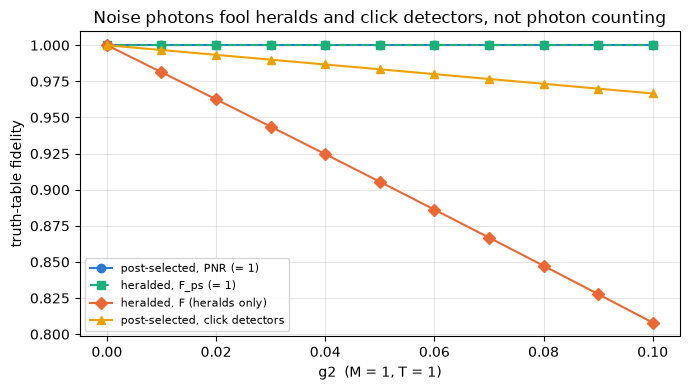

In [14]:
r = run_perceval("post-selected", 1.0, 0.0, 1.0, threshold=True)
check("click detectors, ideal photons: success vs 1/9", r["S"], 1 / 9, tol=1e-12)
check("click detectors, ideal photons: F vs 1", r["F"], 1.0, tol=TOL)
th = {}
for name in REP:
    M, g2, T = SOURCES[name]
    a0, p0 = run_perceval("post-selected", M, 0.0, T, threshold=True), run_perceval("post-selected", M, 0.0, T)
    check(f"{name}, g2 = 0: clicks - PNR (at most 2 photons, must agree)", a0["F"] - p0["F"], 0, tol=TOL)
    th[name] = run_perceval("post-selected", M, g2, T, threshold=True)
    compare(f"{name} / post-selected, click detectors", th[name], run_own("post-selected", M, g2, T, threshold=True))
    pnr = sets[(name, "post-selected")]
    print(f"      F: PNR {pnr['F']:.4f} -> clicks {th[name]['F']:.4f} (change {th[name]['F'] - pnr['F']:+.4f}), "
          f"success x{th[name]['S'] / pnr['S']:.3f}")

g2_clicks = []
for x in g2_grid:
    r, o = run_perceval("post-selected", 1.0, x, 1.0, threshold=True), run_own("post-selected", 1.0, x, 1.0, threshold=True)
    results.append(bool(abs(r["F"] - o["F"]) < TOL))
    g2_clicks.append(r["F"])
print(f"click-detector g2 sweep: {len(g2_grid)} points checked against the own model: "
      f"{'all PASS' if all(results[-len(g2_grid):]) else 'FAIL'}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(g2_grid, [r["F"] for r in sweep[("post-selected", "g2")]], "o-", color=BLUE, label="post-selected, PNR (= 1)")
ax.plot(g2_grid, [r["F_ps"] for r in sweep[("heralded", "g2")]], "s--", color=AQUA, label="heralded, F_ps (= 1)")
ax.plot(g2_grid, [r["F"] for r in sweep[("heralded", "g2")]], "D-", color=ORANGE, label="heralded, F (heralds only)")
ax.plot(g2_grid, g2_clicks, "^-", color=YELLOW, label="post-selected, click detectors")
ax.set_xlabel("g2  (M = 1, T = 1)"); ax.set_ylabel("truth-table fidelity")
ax.set_title("Noise photons fool heralds and click detectors, not photon counting"); ax.grid(alpha=0.3)
ax.legend(fontsize=8); fig.tight_layout(); plt.show()

With number-resolving detectors and no loss, $g^{(2)}$ never lowers the post-selected fidelity: an extra photon cannot pass a photon-number check. With click detectors it costs about $g^{(2)}/3$, because a noise photon can share a detector with a signal photon. For the real sources the change is small (−0.0015 for S_paesani, −0.0042 for S_ring): S_paesani's heavy loss already lets noise photons replace lost ones, and S_ring's low $g^{(2)}$ keeps the extra penalty far below its distinguishability limit.

## 6. What limits each gate

Each imperfection of a source is switched on alone (and $g^{(2)}$ together with loss, since they act jointly); the table lists $1 - F$.

In [15]:
cases = lambda M, g2, T: {"M only": (M, 0, 1), "g2 only": (1, g2, 1), "loss only": (1, 0, T),
                          "g2 + loss": (1, g2, T), "all": (M, g2, T)}
print(f"{'pair':>40} | " + " ".join(f"{c:>9}" for c in cases(1, 0, 1)))
for name in REP:
    for g, thr in (("post-selected", False), ("post-selected", True), ("heralded", False)):
        vals = [1 - run_perceval(g, *v, threshold=thr)["F"] for v in cases(*SOURCES[name]).values()]
        print(f"{name + ' / ' + g + (' (clicks)' if thr else ''):>40} | " + " ".join(f"{v:9.4f}" for v in vals))
check("breakdown 'all' reproduces the source-set result (S_ring heralded)",
      1 - run_perceval("heralded", *SOURCES["S_ring"])["F"], 1 - sets[("S_ring", "heralded")]["F"], tol=TOL)

                                    pair |    M only   g2 only loss only g2 + loss       all
               S_paesani / post-selected |    0.0098    0.0000    0.0000    0.0634    0.0711


      S_paesani / post-selected (clicks) |    0.0098    0.0177    0.0000    0.0649    0.0726
                    S_paesani / heralded |    0.0159    0.1003    0.9953    0.9949    0.9950
                  S_ring / post-selected |    0.0690    0.0000    0.0000    0.0014    0.0701
         S_ring / post-selected (clicks) |    0.0690    0.0067    0.0000    0.0077    0.0742


                       S_ring / heralded |    0.1224    0.0375    0.1693    0.1975    0.2949
PASS  breakdown 'all' reproduces the source-set result (S_ring heralded): simulation = 0.2949, theory = 0.2949


| Gate / source | F | Main limit | Rate × $b^n$ |
|---|---|---|---|
| post-selected / S_paesani | 0.929 | **$g^{(2)}$ together with loss**: a noise photon replaces a lost one and passes post-selection (0.063 of 0.071); either alone costs nothing | 22 /s |
| post-selected / S_ring | 0.930 | **indistinguishability** (0.069 of 0.070) | 270 /s |
| heralded / S_paesani | 0.005 | **loss**: false heralds; F_ps = 0.942 | 0.012 /s |
| heralded / S_ring | 0.705 | **loss** (0.169) and **indistinguishability** (0.122); F_ps = 0.954 | 0.005 /s |
| post-selected, click detectors | 0.927 / 0.926 | adds $\approx g^{(2)}/3$ even without loss | as PNR |

**Conclusion:** with today's sources a post-selected CNOT works at about 93 % truth-table fidelity, limited by distinguishability for the ring and by noise photons replacing lost ones for the silicon source. A heralded gate is only useful once loss is low: its heralds are honest only when every photon survives. Even the ring's on-chip 95 % escape efficiency leaves 0.17 of infidelity from loss, and the four-photon rate makes it impractical with spontaneous sources at these brightnesses.

## Limitations

- **Perceval at very low brightness.** With $b = 0.005$, $M < 1$ and loss, Perceval's brightness model deviates from exact $b^4$ scaling by up to about 1 % for the heralded gate (exact at $M = 1$), and in the unflagged-pulse contrast its heralded fidelity (about $10^{-6}$) differs from our model by up to 2 × 10⁻⁴ relative. Changing `precision` or the global `min_p` does not remove it, so it sits inside Perceval's source sampling of extremely rare states. It is printed below and not counted as a check; no number in the tables above depends on it (the rates use $b^n$, validated at $M = 1$ and for the post-selected gate).
- Truth-table fidelity only; no process fidelity.
- The source model is a mixture model (Pont et al.); herald photons of the Knill gate are assumed to come from the same kind of source with the same loss; loss is uniform over all photons.
- S_ring is a best case: designed $g^{(2)}$, on-chip efficiency only.

In [16]:
M, T, b = SOURCES["S_ring"][0], 0.126, B["S_ring"]            # S_ring's M and b at S_paesani's loss
h1, hb = run_perceval("heralded", M, 0.0, T, 1e-14), run_perceval("heralded", M, 0.0, T, 1e-14, b=b)
print(f"known deviation (not a check): heralded, M = {M}, T = {T}, b = {b}: "
      f"S_ps(b) / (b^4 S_ps(1)) = {hb['S_ps'] / (b ** 4 * h1['S_ps']):.4f}  (exact: 1)")
M, g2, T = SOURCES["S_paesani"]
b = B["S_paesani"]
pb, ob = run_perceval("heralded", M, g2, T, 1e-14, b=b), run_own("heralded", M, g2, T, b=b)
print(f"known deviation (not a check): heralded, unflagged, S_paesani: F = {pb['F']:.4e} (Perceval) vs "
      f"{ob['F']:.4e} (own model)")

known deviation (not a check): heralded, M = 0.92, T = 0.126, b = 0.005: S_ps(b) / (b^4 S_ps(1)) = 0.9873  (exact: 1)


known deviation (not a check): heralded, unflagged, S_paesani: F = 9.5141e-07 (Perceval) vs 9.5159e-07 (own model)


## Validation summary

Every `check` above compared a Perceval result with an analytic formula or with our own independent simulation.

In [17]:
print(f"{sum(results)} of {len(results)} checks passed")
assert all(results), "a simulation disagrees with theory"

193 of 193 checks passed
